## Booking Value Prediction

### Business Question:

**Can we predict the Booking Value of a completed Uber ride using its ride,operational, and booking characteristics ?**

### Target Variable:

**Booking Value**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df= pd.read_csv("../Data/Processed/uber_ride_data.csv")

In [3]:
%config Completer.use_jedi = False

In [4]:
print("Database Shape:", df.shape)
df.head()

Database Shape: (150000, 21)


,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,NaN,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI


In [5]:
completed_df = df[df["Booking Status"] == "Completed"].copy()

print("Completed Rides:", completed_df.shape[0])
completed_df.head()

In [6]:
completed_df["Booking Value"].describe().round(2)

count    93000.00
mean       508.18
std        396.06
min         50.00
25%        234.00
50%        414.00
75%        689.00
max       4277.00
Name: Booking Value, dtype: float64

In [7]:
print("Missing Booking Value:",completed_df["Booking Value"].isna().sum())

Missing Booking Value: 0


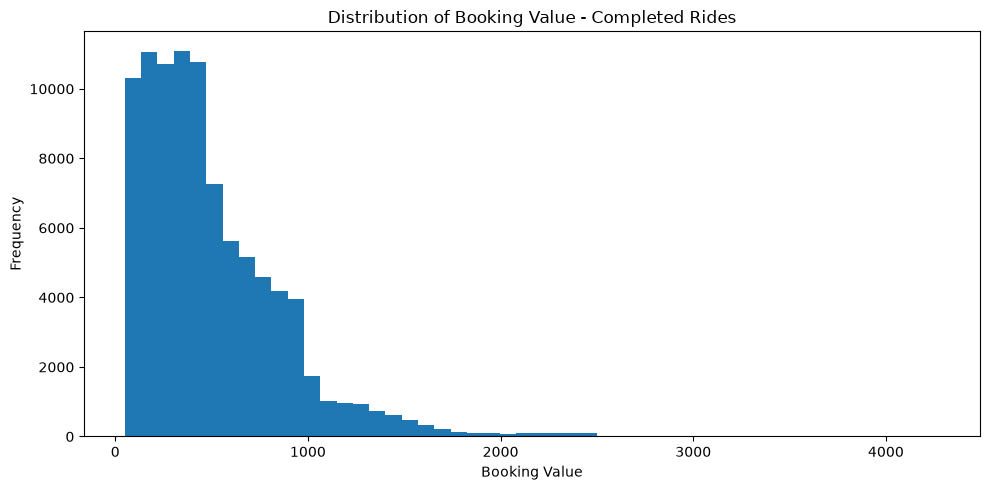

In [8]:
plt.figure(figsize=(10,5))

plt.hist(completed_df["Booking Value"].dropna(),bins=50)

plt.xlabel("Booking Value")
plt.ylabel("Frequency")
plt.title("Distribution of Booking Value - Completed Rides")

plt.tight_layout()
plt.show()

In [9]:
candidate_features = [
     "Ride Distance",
     "Vehicle Type",
     "Pickup Location",
     "Drop Location",
     "Avg VTAT",
     "Avg CTAT",
     "Payment Method"
    ]
completed_df[candidate_features].isna().sum()

Ride Distance      0
Vehicle Type       0
Pickup Location    0
Drop Location      0
Avg VTAT           0
Avg CTAT           0
Payment Method     0
dtype: int64

In [10]:
## Creating Initial Modeling Dataset

In [11]:
reg_df = completed_df[
    [  
        "Booking Value",
        "Ride Distance",
        "Vehicle Type",
        "Pickup Location",
        "Drop Location",
        "Avg VTAT",
        "Avg CTAT",
        "Date",
        "Time",
]].copy()

In [12]:
reg_df.shape

(93000, 9)

In [13]:
reg_df.head()

,Booking Value,Ride Distance,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,Date,Time
2,627.0,13.58,Auto,Khandsa,Malviya Nagar,13.4,25.8,2024-08-23,08:56:10
3,416.0,34.02,Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,2024-10-21,17:17:25
4,737.0,48.21,Bike,Ghitorni Village,Khan Market,5.3,19.6,2024-09-16,22:08:00
5,316.0,4.85,Auto,AIIMS,Narsinghpur,5.1,18.1,2024-02-06,09:44:56
6,640.0,41.24,Go Mini,Vaishali,Punjabi Bagh,7.1,20.4,2024-06-17,15:45:58


## Target & Feature Analysis

### Correlation Analysis

In [14]:
numerical_features = [ "Booking Value","Ride Distance","Avg VTAT","Avg CTAT"]

correlation_pearson = completed_df[numerical_features].corr(method="pearson")

print("Pearson Correlation:")
display(correlation_pearson.round(3))

correlation_spearman = completed_df[numerical_features].corr(method="spearman")

print("Spearman Correlation:")
display(correlation_spearman.round(3))

Pearson Correlation:


,Booking Value,Ride Distance,Avg VTAT,Avg CTAT
Booking Value,1.000,0.006,0.003,0.001
Ride Distance,0.006,1.000,0.004,0.001
Avg VTAT,0.003,0.004,1.000,0.002
Avg CTAT,0.001,0.001,0.002,1.000


Spearman Correlation:


,Booking Value,Ride Distance,Avg VTAT,Avg CTAT
Booking Value,1.000,0.004,0.006,0.002
Ride Distance,0.004,1.000,0.004,0.001
Avg VTAT,0.006,0.004,1.000,0.001
Avg CTAT,0.002,0.001,0.001,1.000


### Ride Distance vs Booking Value

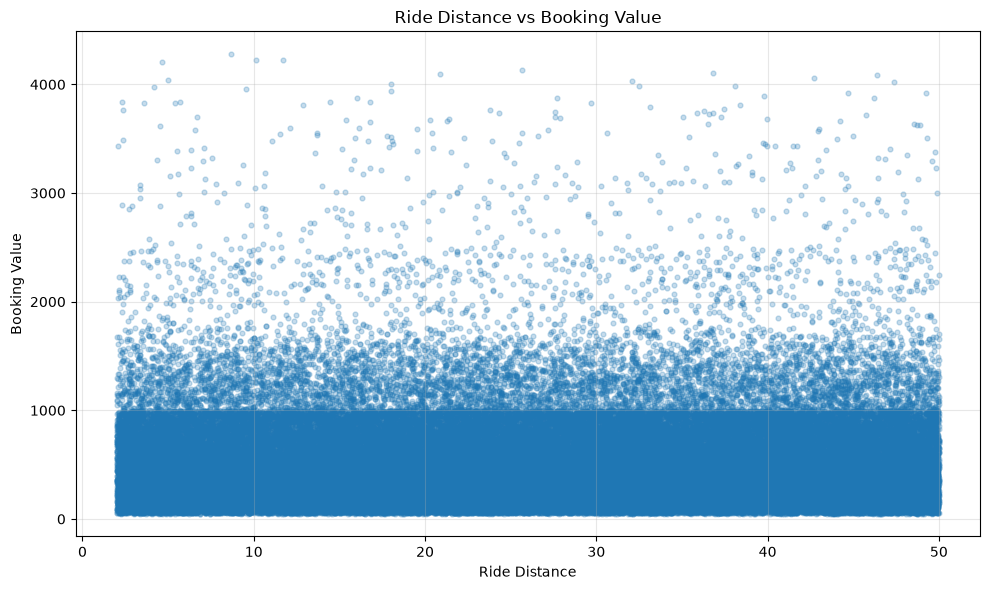

In [15]:
plt.figure(figsize=(10,6))

plt.scatter(completed_df["Ride Distance"], completed_df["Booking Value"], alpha = 0.25, s=12)

plt.xlabel("Ride Distance")
plt.ylabel("Booking Value")
plt.title("Ride Distance vs Booking Value")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

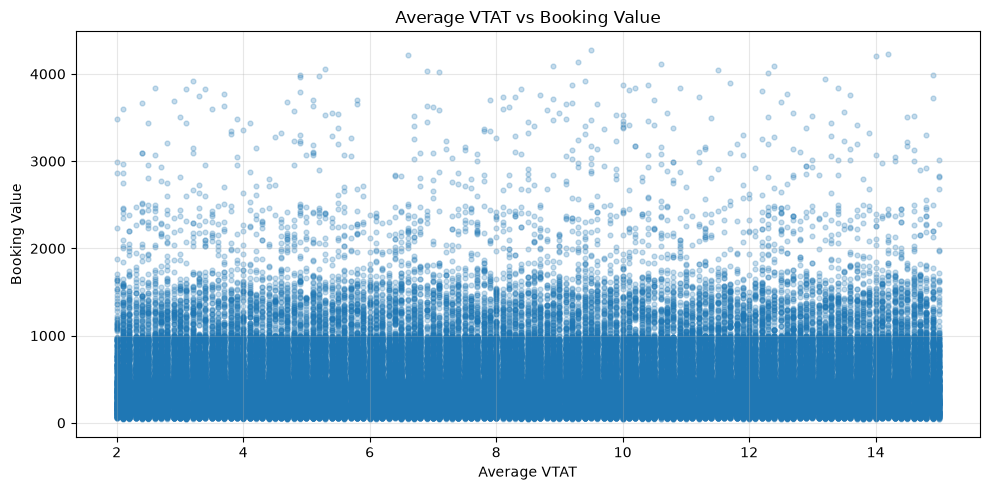

In [16]:
plt.figure(figsize=(10,5))

plt.scatter(completed_df["Avg VTAT"], completed_df["Booking Value"], alpha = 0.25, s=12)

plt.xlabel("Average VTAT")
plt.ylabel("Booking Value")
plt.title("Average VTAT vs Booking Value")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

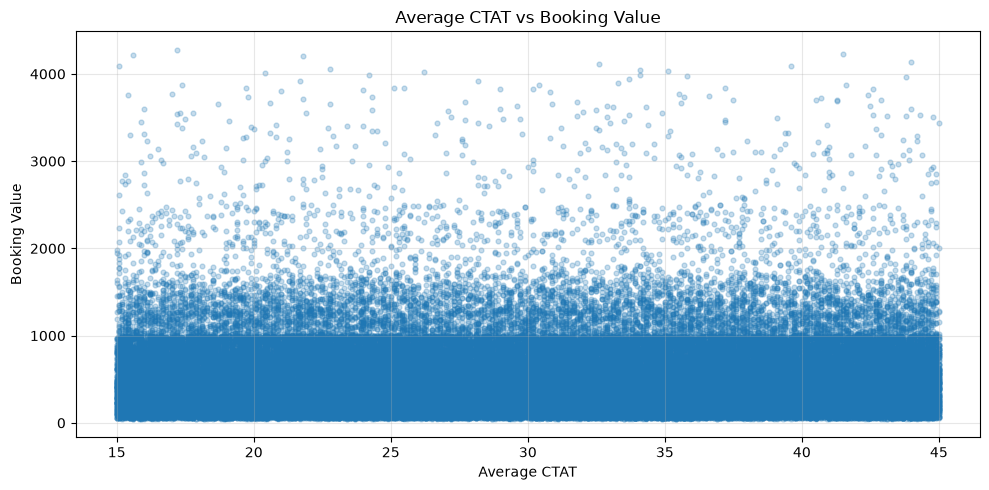

In [17]:
plt.figure(figsize=(10,5))

plt.scatter(completed_df["Avg CTAT"], completed_df["Booking Value"], alpha = 0.25, s=12)

plt.xlabel("Average CTAT")
plt.ylabel("Booking Value")
plt.title("Average CTAT vs Booking Value")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Vehicle Type vs Booking Value

In [18]:
vehicle_booking_value = (completed_df.groupby("Vehicle Type")["Booking Value"].agg(["count","mean","median"]).sort_values("mean",ascending=False))

vehicle_booking_value.round(2)

,count,mean,median
Vehicle Type,,,
Go Sedan,16676,512.03,417.0
Premier Sedan,11252,509.57,417.0
Bike,14034,509.11,415.0
Go Mini,18549,507.38,412.0
Auto,23155,506.48,413.0
Uber XL,2783,505.30,411.0
eBike,6551,503.46,409.0


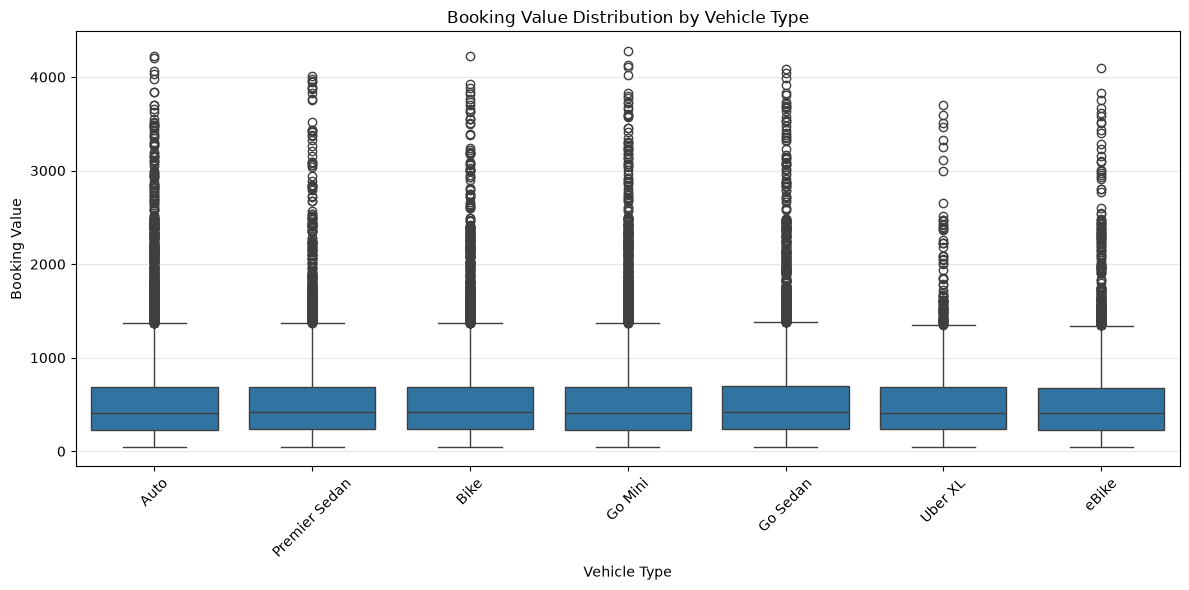

In [19]:
plt.figure(figsize=(12,6))

sns.boxplot(data=completed_df,x="Vehicle Type",y="Booking Value")

plt.xlabel("Vehicle Type")
plt.ylabel("Booking Value")
plt.title("Booking Value Distribution by Vehicle Type")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Payment Method vs Booking Value

In [20]:
payment_booking_value = (completed_df.groupby("Payment Method")["Booking Value"].agg(["count","mean","median"]).sort_values("mean",ascending=False))

payment_booking_value.round(2)

,count,mean,median
Payment Method,,,
Credit Card,9320,510.06,416.0
Cash,23114,508.61,416.0
UPI,41834,508.55,413.0
Uber Wallet,11206,505.90,413.0
Debit Card,7526,505.86,412.0


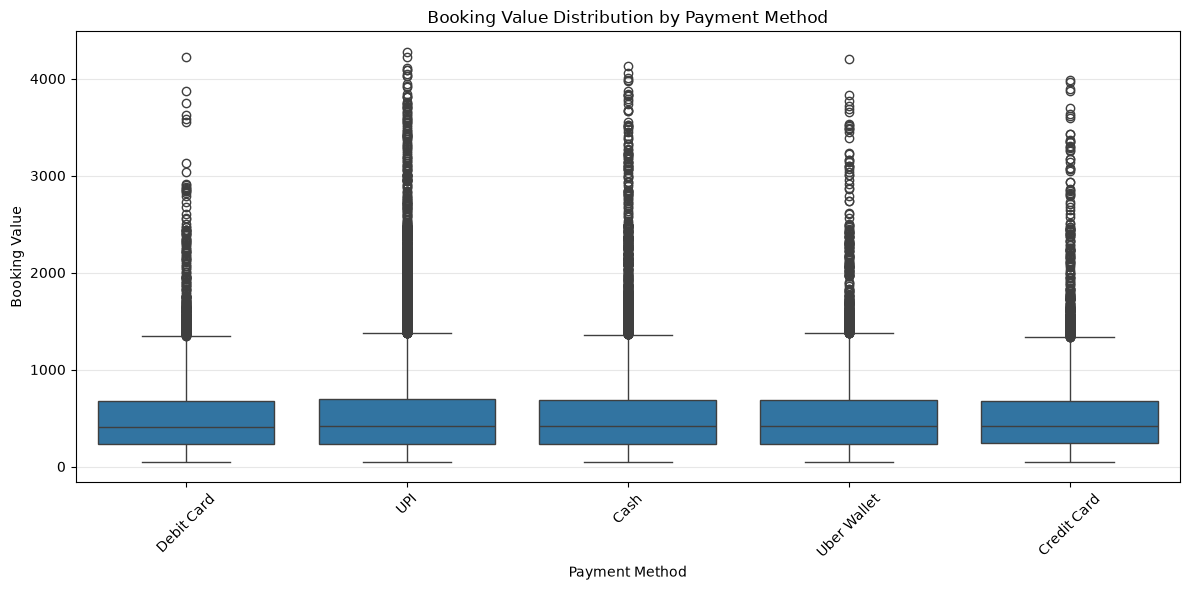

In [21]:
plt.figure(figsize=(12,6))

sns.boxplot(data=completed_df,x="Payment Method",y="Booking Value")

plt.xlabel("Payment Method")
plt.ylabel("Booking Value")
plt.title("Booking Value Distribution by Payment Method")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Pickup Location vs Booking Value

In [22]:
top_pickup_locations = (completed_df["Pickup Location"].value_counts().head(10).index)

pickup_booking_value = (completed_df[completed_df["Pickup Location"].isin(top_pickup_locations)].groupby("Pickup Location")["Booking Value"].agg(["count","mean","median"]).sort_values("mean",ascending=False) )

pickup_booking_value.round(2)

,count,mean,median
Pickup Location,,,
Badarpur,567,526.12,442.0
Barakhamba Road,594,521.40,424.5
Khandsa,600,515.07,418.0
Subhash Chowk,582,513.79,422.5
Lok Kalyan Marg,564,510.33,415.0
Ashok Park Main,568,509.58,432.0
Dwarka Sector 21,565,509.48,411.0
Madipur,579,489.23,406.0
Mehrauli,574,482.12,397.5


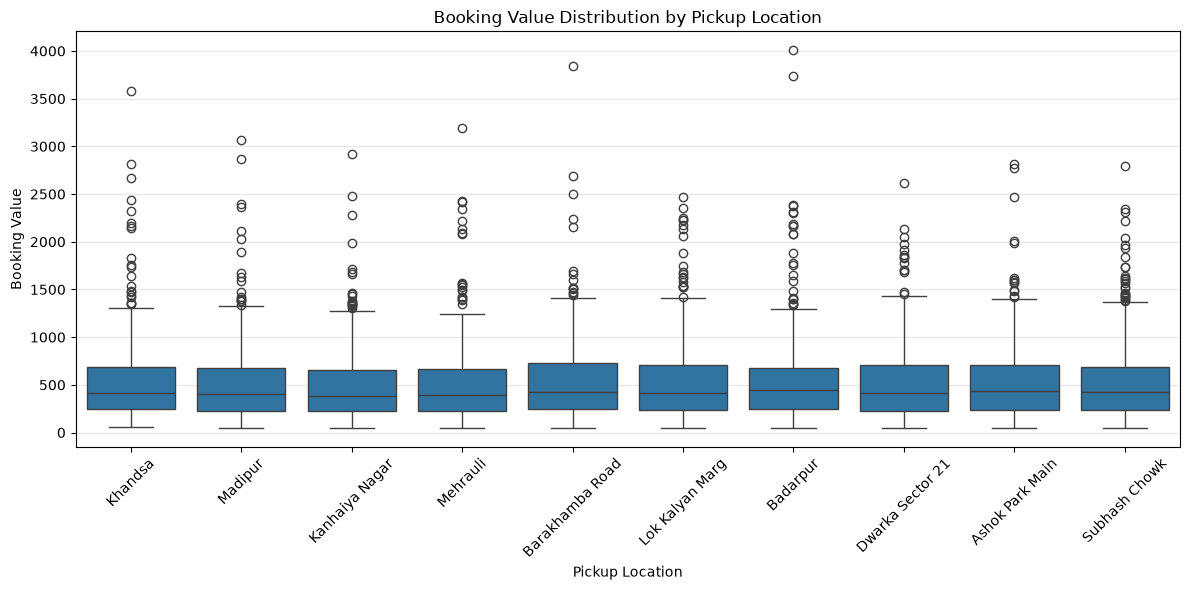

In [23]:
plt.figure(figsize=(12,6))

sns.boxplot(data= completed_df[completed_df["Pickup Location"].isin(top_pickup_locations)],x="Pickup Location",y="Booking Value")

plt.xlabel("Pickup Location")
plt.ylabel("Booking Value")
plt.title("Booking Value Distribution by Pickup Location")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Drop Location vs Booking Value

In [24]:
top_drop_locations = (completed_df["Drop Location"].value_counts().head(10).index)

drop_booking_value = (completed_df[completed_df["Drop Location"].isin(top_drop_locations)].groupby("Drop Location")["Booking Value"].agg(["count","mean","median"]).sort_values("mean",ascending=False) )

drop_booking_value.round(2)

,count,mean,median
Drop Location,,,
Narsinghpur,574,566.78,445.5
Lajpat Nagar,572,521.97,432.0
Sarai Kale Khan,573,519.47,416.0
Sultanpur,584,512.49,416.0
Noida Extension,579,512.24,416.0
Dwarka Mor,574,487.38,400.0
Cyber Hub,571,483.69,404.0
Ashram,592,482.08,407.5
Kashmere Gate ISBT,570,479.65,397.5


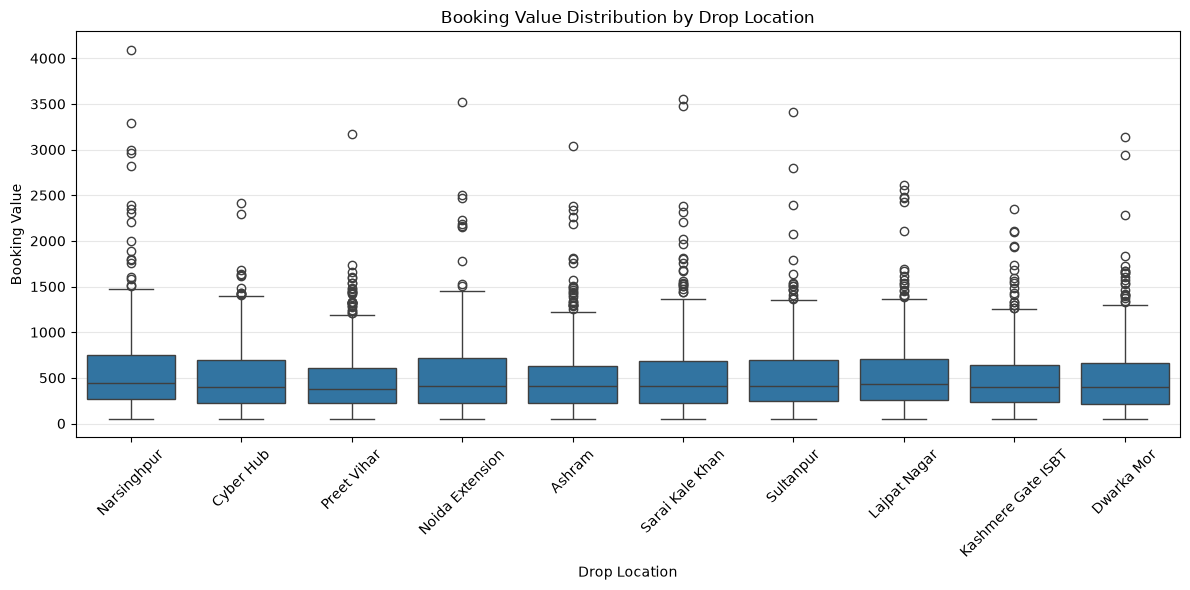

In [25]:
plt.figure(figsize=(12,6))

sns.boxplot(data= completed_df[completed_df["Drop Location"].isin(top_drop_locations)],x="Drop Location",y="Booking Value")

plt.xlabel("Drop Location")
plt.ylabel("Booking Value")
plt.title("Booking Value Distribution by Drop Location")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [26]:
for feature in ["Vehicle Type","Payment Method","Pickup Location","Drop Location"]:
    print(f"\n======{feature} =====")
    result= (completed_df.groupby("Payment Method")["Booking Value"].agg(["count","mean","median"]).sort_values("mean",ascending=False))

    display(result.round(2))


======Vehicle Type =====


,count,mean,median
Payment Method,,,
Credit Card,9320,510.06,416.0
Cash,23114,508.61,416.0
UPI,41834,508.55,413.0
Uber Wallet,11206,505.90,413.0
Debit Card,7526,505.86,412.0



======Payment Method =====


,count,mean,median
Payment Method,,,
Credit Card,9320,510.06,416.0
Cash,23114,508.61,416.0
UPI,41834,508.55,413.0
Uber Wallet,11206,505.90,413.0
Debit Card,7526,505.86,412.0



======Pickup Location =====


,count,mean,median
Payment Method,,,
Credit Card,9320,510.06,416.0
Cash,23114,508.61,416.0
UPI,41834,508.55,413.0
Uber Wallet,11206,505.90,413.0
Debit Card,7526,505.86,412.0



======Drop Location =====


,count,mean,median
Payment Method,,,
Credit Card,9320,510.06,416.0
Cash,23114,508.61,416.0
UPI,41834,508.55,413.0
Uber Wallet,11206,505.90,413.0
Debit Card,7526,505.86,412.0


### Time Based Feature Relationship

In [27]:
time_analysis_df= completed_df.copy()

time_analysis_df["Date"] = pd.to_datetime(time_analysis_df["Date"],errors="coerce")
time_analysis_df["Time"] = pd.to_datetime(time_analysis_df["Time"],errors="coerce")

time_analysis_df["Booking_Hour"]= time_analysis_df["Time"].dt.hour
time_analysis_df["Booking_Month"]= time_analysis_df["Date"].dt.month
time_analysis_df["Day_of_Week"]= time_analysis_df["Date"].dt.dayofweek
time_analysis_df["Is_Weekend"]= (time_analysis_df["Day_of_Week"] >=5).astype(int)

C:\Users\ashut\AppData\Local\Temp\ipykernel_7712\2038716267.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  time_analysis_df["Time"] = pd.to_datetime(time_analysis_df["Time"],errors="coerce")


In [28]:
## Booking Value by Hour

In [29]:
hourly_booking_value= (time_analysis_df.groupby("Booking_Hour")["Booking Value"].agg(["count","mean","median"]))

hourly_booking_value.round(2)

,count,mean,median
Booking_Hour,,,
0,858,507.84,412.0
1,828,514.41,420.0
2,853,509.67,429.0
3,860,504.32,406.5
4,830,503.91,403.0
5,1715,499.31,396.0
6,2609,515.49,417.0
7,3346,500.84,412.0
8,4267,511.78,414.0


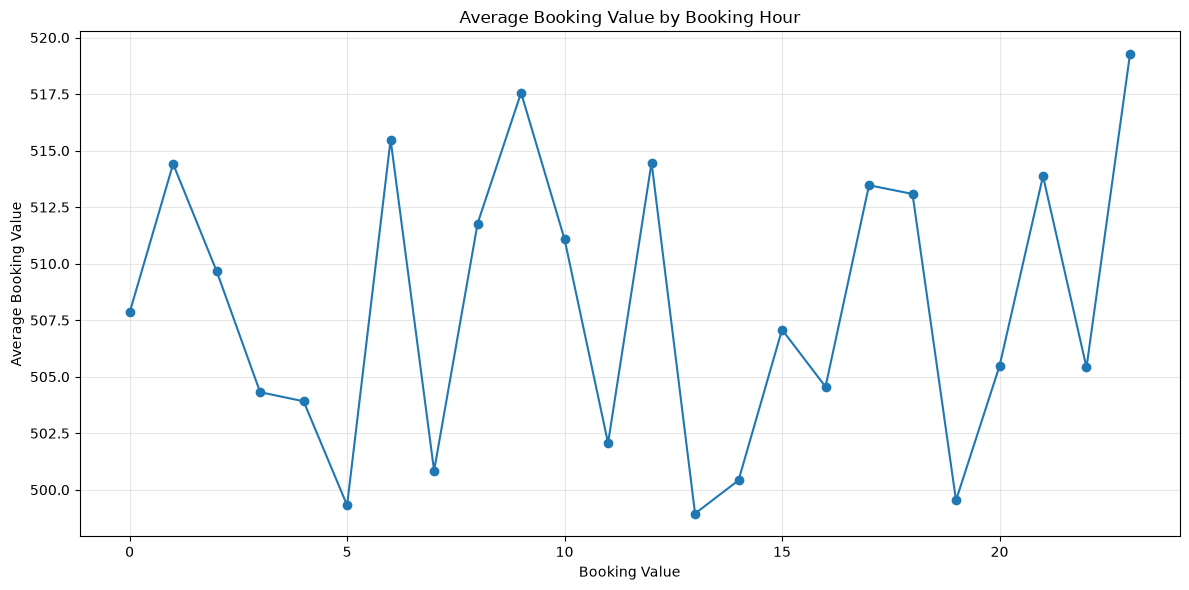

In [30]:
plt.figure(figsize=(12,6))

plt.plot(hourly_booking_value.index, hourly_booking_value["mean"],marker="o")

plt.xlabel("Booking Value")
plt.ylabel("Average Booking Value")
plt.title("Average Booking Value by Booking Hour")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
## Booking Value by Day Type

In [32]:
weekend_booking_value= (time_analysis_df.groupby("Is_Weekend")["Booking Value"].agg(["count","mean","median"]))

weekend_booking_value.round(2)

,count,mean,median
Is_Weekend,,,
0,66244,448.67,377.0
1,26756,655.51,551.0


In [33]:
feature_target_summary =[]

for feature in ["Ride Distance","Avg VTAT","Avg CTAT"]:
    pearson_value = completed_df[[feature,"Booking Value"]].corr(method="pearson").iloc[0,1]
    spearman_value = completed_df[[feature,"Booking Value"]].corr(method="spearman").iloc[0,1]

    feature_target_summary.append({"Feature": feature, "Pearson Correlation": pearson_value, "Spearman Correlation": spearman_value})

feature_target_summary = pd.DataFrame(feature_target_summary)
feature_target_summary.round(3)

,Feature,Pearson Correlation,Spearman Correlation
0,Ride Distance,0.006,0.004
1,Avg VTAT,0.003,0.006
2,Avg CTAT,0.001,0.002


## Feature Engineering

In [34]:
reg_df = completed_df[[
    "Booking Value",
    "Ride Distance",
    "Vehicle Type",
    "Pickup Location",
    "Drop Location",
    "Avg VTAT",
    "Avg CTAT",
    "Payment Method",
    "Date",
    "Time"
]].copy()

print(reg_df.shape)
reg_df.head()

(93000, 10)


,Booking Value,Ride Distance,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,Payment Method,Date,Time
2,627.0,13.58,Auto,Khandsa,Malviya Nagar,13.4,25.8,Debit Card,2024-08-23,08:56:10
3,416.0,34.02,Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,UPI,2024-10-21,17:17:25
4,737.0,48.21,Bike,Ghitorni Village,Khan Market,5.3,19.6,UPI,2024-09-16,22:08:00
5,316.0,4.85,Auto,AIIMS,Narsinghpur,5.1,18.1,UPI,2024-02-06,09:44:56
6,640.0,41.24,Go Mini,Vaishali,Punjabi Bagh,7.1,20.4,UPI,2024-06-17,15:45:58


In [35]:
reg_df["Date"] = pd.to_datetime(reg_df["Date"],errors="coerce")
reg_df["Time"] = pd.to_datetime(reg_df["Time"],errors="coerce")

reg_df["Booking_Hour"]= reg_df["Time"].dt.hour
reg_df["Booking_Month"]= reg_df["Date"].dt.month
reg_df["Day_of_Week"]= reg_df["Date"].dt.dayofweek
reg_df["Is_Weekend"]= (reg_df["Day_of_Week"] >=5).astype(int)

C:\Users\ashut\AppData\Local\Temp\ipykernel_7712\2742244719.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  reg_df["Time"] = pd.to_datetime(reg_df["Time"],errors="coerce")


In [36]:
def get_time_period(hour):
    if 5<= hour <12:
        return "Morning"
    elif 12<= hour <17:
        return "Evening"
    else:
        return "Night"

reg_df["Time_Period"] = reg_df["Booking_Hour"].apply(get_time_period)

reg_df["Time_Period"].value_counts()

Time_Period
Night      41691
Morning    28258
Evening    23051
Name: count, dtype: int64

In [37]:
## Route Feature

In [38]:
reg_df["Route"]= (reg_df["Pickup Location"].astype(str)+ "->" + reg_df["Drop Location"].astype(str))
reg_df["Route"].nunique()

29269

In [39]:
reg_df["Route"].value_counts().head(10)

Route
DLF City Court->Bhiwadi             13
Rohini West->Sohna Road             13
Subhash Chowk->IGNOU Road           11
Noida Sector 62->Sarai Kale Khan    11
Lok Kalyan Marg->Jhilmil            11
Ambience Mall->Akshardham           11
Rithala->Udyog Vihar Phase 4        11
Sushant Lok->Sarai Kale Khan        11
Jama Masjid->Khan Market            10
Dwarka Sector 21->Govindpuri        10
Name: count, dtype: int64

In [40]:
## Log Transform Ride Distance

In [41]:
reg_df["Ride_Distance_log"] = np.log1p(reg_df["Ride Distance"])

reg_df[["Ride Distance","Ride_Distance_log"]].head()

,Ride Distance,Ride_Distance_log
2,13.58,2.679651
3,34.02,3.555919
4,48.21,3.896097
5,4.85,1.766442
6,41.24,3.743368


In [42]:
## Creating Distance Category

In [43]:
reg_df["Distance_Category"] = pd.cut(reg_df["Ride Distance"],
                                     bins=[-np.inf,3,8,15,30,np.inf],
                                     labels= ["Very Short",
                                             "Short",
                                             "Medium",
                                             "Long",
                                             "Very Long"])
reg_df["Distance_Category"].value_counts()

Distance_Category
Very Long     38748
Long          29201
Medium        13421
Short          9703
Very Short     1927
Name: count, dtype: int64

In [44]:
## Log Features on VTAT & CTAT

In [45]:
reg_df["Avg_VTAT_Log"] = np.log1p(reg_df["Avg VTAT"])
reg_df["Avg_CTAT_Log"] = np.log1p(reg_df["Avg CTAT"])

In [46]:
## Creating Location Frequency Features

In [47]:
# Pickup Frequency

In [48]:
pickup_frequency = (reg_df["Pickup Location"].value_counts(normalize=True))

reg_df["Pickup_Frequency"] = (reg_df["Pickup Location"].map(pickup_frequency))

In [49]:
# Drop Frequency

In [50]:
drop_frequency = (reg_df["Drop Location"].value_counts(normalize=True))

reg_df["Drop_Frequency"] = (reg_df["Drop Location"].map(drop_frequency))

In [51]:
print("Number of features:", reg_df.shape[1])

print("\ncolumns:")
for column in reg_df.columns:
    print(column)

Number of features: 22

columns:
Booking Value
Ride Distance
Vehicle Type
Pickup Location
Drop Location
Avg VTAT
Avg CTAT
Payment Method
Date
Time
Booking_Hour
Booking_Month
Day_of_Week
Is_Weekend
Time_Period
Route
Ride_Distance_log
Distance_Category
Avg_VTAT_Log
Avg_CTAT_Log
Pickup_Frequency
Drop_Frequency


In [52]:
reg_df.head()

,Booking Value,Ride Distance,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,Payment Method,Date,Time,...,Day_of_Week,Is_Weekend,Time_Period,Route,Ride_Distance_log,Distance_Category,Avg_VTAT_Log,Avg_CTAT_Log,Pickup_Frequency,Drop_Frequency
2,627.0,13.58,Auto,Khandsa,Malviya Nagar,13.4,25.8,Debit Card,2024-08-23,2026-10-17 08:56:10,...,4,0,Morning,Khandsa->Malviya Nagar,2.679651,Medium,2.667228,3.288402,0.006452,0.005624
3,416.0,34.02,Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,UPI,2024-10-21,2026-10-17 17:17:25,...,0,0,Night,Central Secretariat->Inderlok,3.555919,Very Long,2.646175,3.384390,0.005602,0.005613
4,737.0,48.21,Bike,Ghitorni Village,Khan Market,5.3,19.6,UPI,2024-09-16,2026-10-17 22:08:00,...,0,0,Night,Ghitorni Village->Khan Market,3.896097,Very Long,1.840550,3.025291,0.005333,0.005968
5,316.0,4.85,Auto,AIIMS,Narsinghpur,5.1,18.1,UPI,2024-02-06,2026-10-17 09:44:56,...,1,0,Morning,AIIMS->Narsinghpur,1.766442,Short,1.808289,2.949688,0.006043,0.006172
6,640.0,41.24,Go Mini,Vaishali,Punjabi Bagh,7.1,20.4,UPI,2024-06-17,2026-10-17 15:45:58,...,0,0,Evening,Vaishali->Punjabi Bagh,3.743368,Very Long,2.091864,3.063391,0.005742,0.006032


In [53]:
reg_df.isna().sum().sort_values(ascending=False)

Booking Value        0
Ride Distance        0
Vehicle Type         0
Pickup Location      0
Drop Location        0
Avg VTAT             0
Avg CTAT             0
Payment Method       0
Date                 0
Time                 0
Booking_Hour         0
Booking_Month        0
Day_of_Week          0
Is_Weekend           0
Time_Period          0
Route                0
Ride_Distance_log    0
Distance_Category    0
Avg_VTAT_Log         0
Avg_CTAT_Log         0
Pickup_Frequency     0
Drop_Frequency       0
dtype: int64

In [54]:
reg_df = reg_df.drop(columns=["Date","Time"])
reg_df.columns

Index(['Booking Value', 'Ride Distance', 'Vehicle Type', 'Pickup Location',
       'Drop Location', 'Avg VTAT', 'Avg CTAT', 'Payment Method',
       'Booking_Hour', 'Booking_Month', 'Day_of_Week', 'Is_Weekend',
       'Time_Period', 'Route', 'Ride_Distance_log', 'Distance_Category',
       'Avg_VTAT_Log', 'Avg_CTAT_Log', 'Pickup_Frequency', 'Drop_Frequency'],
      dtype='str')

In [55]:
reg_df.to_csv("../Data/Processed/booking_value_regression_features.csv",index=False)
print("Engineered Regression Dataset saved successfully ")

Engineered Regression Dataset saved successfully 


### A.3 Modeling Insight

### Train/Test Preperation

In [56]:
X = reg_df.drop(columns="Booking Value")
y = reg_df["Booking Value"]

print("Feature Dataset shape:",X.shape)
print("Target Feature:",y.shape)


Feature Dataset shape: (93000, 19)
Target Feature: (93000,)


In [57]:
print("Target Variable:")
display(y.head())

print("\nFeature Variable:")
display(X.head())

Target Variable:


2    627.0
3    416.0
4    737.0
5    316.0
6    640.0
Name: Booking Value, dtype: float64


Feature Variable:


,Ride Distance,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,Payment Method,Booking_Hour,Booking_Month,Day_of_Week,Is_Weekend,Time_Period,Route,Ride_Distance_log,Distance_Category,Avg_VTAT_Log,Avg_CTAT_Log,Pickup_Frequency,Drop_Frequency
2,13.58,Auto,Khandsa,Malviya Nagar,13.4,25.8,Debit Card,8,8,4,0,Morning,Khandsa->Malviya Nagar,2.679651,Medium,2.667228,3.288402,0.006452,0.005624
3,34.02,Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,UPI,17,10,0,0,Night,Central Secretariat->Inderlok,3.555919,Very Long,2.646175,3.384390,0.005602,0.005613
4,48.21,Bike,Ghitorni Village,Khan Market,5.3,19.6,UPI,22,9,0,0,Night,Ghitorni Village->Khan Market,3.896097,Very Long,1.840550,3.025291,0.005333,0.005968
5,4.85,Auto,AIIMS,Narsinghpur,5.1,18.1,UPI,9,2,1,0,Morning,AIIMS->Narsinghpur,1.766442,Short,1.808289,2.949688,0.006043,0.006172
6,41.24,Go Mini,Vaishali,Punjabi Bagh,7.1,20.4,UPI,15,6,0,0,Evening,Vaishali->Punjabi Bagh,3.743368,Very Long,2.091864,3.063391,0.005742,0.006032


In [58]:
## Identifying Numerical and Categorical Feature

In [59]:
print(X.dtypes)

Ride Distance         float64
Vehicle Type              str
Pickup Location           str
Drop Location             str
Avg VTAT              float64
Avg CTAT              float64
Payment Method            str
Booking_Hour            int32
Booking_Month           int32
Day_of_Week             int32
Is_Weekend              int64
Time_Period               str
Route                     str
Ride_Distance_log     float64
Distance_Category    category
Avg_VTAT_Log          float64
Avg_CTAT_Log          float64
Pickup_Frequency      float64
Drop_Frequency        float64
dtype: object


In [60]:
categorical_features = X.select_dtypes(include=["object","category"]).columns.tolist()
numerical_features = X.select_dtypes(include=["int32","int64","float64"]).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['Vehicle Type', 'Pickup Location', 'Drop Location', 'Payment Method', 'Time_Period', 'Route', 'Distance_Category']

Numerical Features:
['Ride Distance', 'Avg VTAT', 'Avg CTAT', 'Booking_Hour', 'Booking_Month', 'Day_of_Week', 'Is_Weekend', 'Ride_Distance_log', 'Avg_VTAT_Log', 'Avg_CTAT_Log', 'Pickup_Frequency', 'Drop_Frequency']


C:\Users\ashut\AppData\Local\Temp\ipykernel_7712\1170005421.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object","category"]).columns.tolist()


In [61]:
## Train/Test Split

In [62]:
from sklearn.model_selection import train_test_split

In [63]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [64]:
print("X_train:",X_train.shape)
print("X_test:",X_test.shape)
print("y_train:",y_train.shape)
print("y_test:",y_test.shape)

X_train: (74400, 19)
X_test: (18600, 19)
y_train: (74400,)
y_test: (18600,)


In [65]:
print("Training Target Statistics:")
display(y_train.describe().round(2))

print("\nTesting Target Statistics:")
display(y_test.describe().round(2))

Training Target Statistics:


count    74400.00
mean       508.78
std        395.22
min         50.00
25%        235.00
50%        415.00
75%        689.00
max       4277.00
Name: Booking Value, dtype: float64


Testing Target Statistics:


count    18600.00
mean       505.76
std        399.40
min         50.00
25%        230.00
50%        409.00
75%        688.00
max       4228.00
Name: Booking Value, dtype: float64

In [66]:
print("Training Mean:",round(y_train.mean(),2))
print("Testing Mean:",round(y_test.mean(),2))

print("Mean Difference:",round(abs(y_train.mean()-y_test.mean()),2))


Training Mean: 508.78
Testing Mean: 505.76
Mean Difference: 3.02


In [67]:
## Verifying Data Leakage between Train & Test

In [68]:
print("Training  rows:",len(X_train))
print("Testing rows:",len(X_test))

print("Total rows:", len(X_train) + len(X_test))

Training  rows: 74400
Testing rows: 18600
Total rows: 93000


In [69]:
print("Training  rows:",X_train.index.nunique())
print("Testing rows:",X_test.index.nunique())

print("overlapping indices:", len(X_train.index.intersection(X_test.index)))

Training  rows: 74400
Testing rows: 18600
overlapping indices: 0


In [70]:
for feature in categorical_features:
    print(
        f"{feature}:"
        f"{X_train[feature].nunique()} unique values")

Vehicle Type:7 unique values
Pickup Location:176 unique values
Drop Location:176 unique values
Payment Method:5 unique values
Time_Period:3 unique values
Route:28027 unique values
Distance_Category:5 unique values


In [71]:
train_data = X_train.copy()
train_data["Booking Value"]= y_train

test_data = X_test.copy()
test_data["Booking Value"] = y_test

train_data.to_csv("../Data/Processed/booking_value_train.csv",index=False)
test_data.to_csv("../Data/Processed/booking_value_test.csv",index=False)

print("Train and Test Datasets saved successfully.")

Train and Test Datasets saved successfully.


## Preprocessing & Regression Models

### Handling High-Cardinality Features

In [72]:
categorical_features= X_train.select_dtypes(include=["object"]).columns.tolist()
for col in categorical_features:
    print(
        f"{col}:"
        f"{X_train[col].nunique()} unique categories")

Vehicle Type:7 unique categories
Pickup Location:176 unique categories
Drop Location:176 unique categories
Payment Method:5 unique categories
Time_Period:3 unique categories
Route:28027 unique categories


C:\Users\ashut\AppData\Local\Temp\ipykernel_7712\1029049040.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features= X_train.select_dtypes(include=["object"]).columns.tolist()


-------------------------------------------------------------------------
Route feature has approximately 28077 unique values,making it a very high-cardinality categorical feature. A direct one-hot encoding of all routes 
could create ten of thousands of additional features and unneccesarily increase memory usage and model complexity.

Since **Pickup Location** and **Drop Location** already capture the geographic components of the route, **Route** is removed from the modeling dataset.

---------------------------------------------------------------------------


In [73]:
X_train = X_train.drop(columns=["Route"],errors="ignore")
X_test = X_test.drop(columns=["Route"],errors="ignore")

In [74]:
categorical_features = X_train.select_dtypes(include=["object","category"]).columns.tolist()
numerical_features = X_train.select_dtypes(include = ["int32","int64","float64"]).columns.tolist()

print("Categorical Features:-", categorical_features)
print("Numerical Features:-",numerical_features)


Categorical Features:- ['Vehicle Type', 'Pickup Location', 'Drop Location', 'Payment Method', 'Time_Period', 'Distance_Category']
Numerical Features:- ['Ride Distance', 'Avg VTAT', 'Avg CTAT', 'Booking_Hour', 'Booking_Month', 'Day_of_Week', 'Is_Weekend', 'Ride_Distance_log', 'Avg_VTAT_Log', 'Avg_CTAT_Log', 'Pickup_Frequency', 'Drop_Frequency']


C:\Users\ashut\AppData\Local\Temp\ipykernel_7712\3849396946.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=["object","category"]).columns.tolist()


In [75]:
## Correct Frequency Encoding Leakage

In [76]:
X_train = X_train.drop(columns=["Pickup_Frequency","Drop_Frequency"],errors="ignore")
X_test = X_test.drop(columns=["Pickup_Frequency","Drop_Frequency"],errors="ignore")

In [77]:
pickup_frequency= X_train["Pickup Location"].value_counts(normalize=True)
drop_frequency= X_train["Drop Location"].value_counts(normalize=True)

In [78]:
X_train["Pickup_Frequency"]= (X_train["Pickup Location"].map(pickup_frequency).fillna(0))
X_test["Pickup_Frequency"] = (X_test["Pickup Location"].map(pickup_frequency).fillna(0))

X_train["Drop_Frequency"]= (X_train["Drop Location"].map(drop_frequency).fillna(0))
X_test["Drop_Frequency"]= (X_test["Drop Location"].map(drop_frequency).fillna(0))

In [79]:
categorical_features = X_train.select_dtypes(include=["object","category"]).columns.tolist()
numerical_features = X_train.select_dtypes(include = ["int32","int64","float64"]).columns.tolist()

print("Categorical Features:-", categorical_features)
print("\nNumerical Features:-",numerical_features)

Categorical Features:- ['Vehicle Type', 'Pickup Location', 'Drop Location', 'Payment Method', 'Time_Period', 'Distance_Category']

Numerical Features:- ['Ride Distance', 'Avg VTAT', 'Avg CTAT', 'Booking_Hour', 'Booking_Month', 'Day_of_Week', 'Is_Weekend', 'Ride_Distance_log', 'Avg_VTAT_Log', 'Avg_CTAT_Log', 'Pickup_Frequency', 'Drop_Frequency']


C:\Users\ashut\AppData\Local\Temp\ipykernel_7712\1438814458.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=["object","category"]).columns.tolist()


### Numerical Feature Preprocessing

In [80]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("Scaler", StandardScaler())
    
])

### Categorical Feature Preprocessing

In [81]:
from sklearn.preprocessing import OneHotEncoder

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore",min_frequency=20))
    ]
)

In [82]:
## Combining Processing Steps

In [83]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers =[
        (
            "numerical",
            numerical_transformer,
            numerical_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [84]:
preprocessor.fit(X_train, y_train)

X_train_transformed = preprocessor.transform(X_train)

print("Original training rows:", X_train.shape[0])

Original training rows: 74400


In [85]:
features_names = preprocessor.get_feature_names_out()
print("Total Transformed features:", len(features_names))

Total Transformed features: 384


In [86]:
for prefix in ["numerical__","categorical__"]:
    count= sum(feature.startswith(prefix)
              for feature in features_names)
    print(f"{prefix}: {count} features")

numerical__: 12 features
categorical__: 372 features


## Linear Regression

In [87]:
from sklearn.linear_model import LinearRegression

In [88]:
linear_model = Pipeline(steps=[("preprocessor",preprocessor),("model",LinearRegression())])

In [89]:
linear_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['Ride Distance','Vehicle Type','Pickup Location',...,'Avg_CTAT_Log', 'Pickup_Frequency','Drop_Frequency']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be aut

In [90]:
y_pred_linear = linear_model.predict(X_test)

In [91]:
print(y_pred_linear)

[461.91097576 435.86025455 464.84696602 ... 469.79767121 473.29531101
 448.70264155]


## Ridge Regression

In [92]:
from sklearn.linear_model import Ridge

In [93]:
ridge_model = Pipeline(steps=[("preprocessor",preprocessor),("model",Ridge(alpha=10.0))])

In [94]:
ridge_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['Ride Distance','Vehicle Type','Pickup Location',...,'Avg_CTAT_Log', 'Pickup_Frequency','Drop_Frequency']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be aut

In [95]:
y_pred_ridge= ridge_model.predict(X_test)

In [96]:
print(y_pred_ridge)

[461.61334901 435.69254157 464.83656576 ... 469.33934473 472.83592008
 448.99385045]


## Random Forest Regression

In [97]:
from sklearn.ensemble import RandomForestRegressor

In [98]:
random_forest_model= Pipeline(steps=[("preprocessor",preprocessor),
                                     ("model",RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=-1,max_features="sqrt"))])

In [99]:
random_forest_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['Ride Distance','Vehicle Type','Pickup Location',...,'Avg_CTAT_Log', 'Pickup_Frequency','Drop_Frequency']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be aut

In [100]:
y_pred_rf = random_forest_model.predict(X_test)

In [101]:
import joblib

joblib.dump(linear_model,"../Data/Processed/booking_value_linear_model.pkl")
joblib.dump(ridge_model,"../Data/Processed/booking_value_ridge_model.pkl")
joblib.dump(random_forest_model,"../Data/Processed/booking_value_random_forest_model.pkl")

['../Data/Processed/booking_value_random_forest_model.pkl']

## Model Evaluation & Comparison

### Calculate Model Performance

In [109]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

models_predictions = {
    "Linear Regression": y_pred_linear,
    "Ridge Regression": y_pred_ridge,
    "Random Forest": y_pred_rf
}

for model_name, predictions in models_predictions.items():
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)
    
    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

results_df = pd.DataFrame(results)
results_df.round(3)

,Model,MAE,RMSE,R²
0,Linear Regression,278.243,389.297,0.050
1,Ridge Regression,278.199,389.252,0.050
2,Random Forest,279.363,391.684,0.038


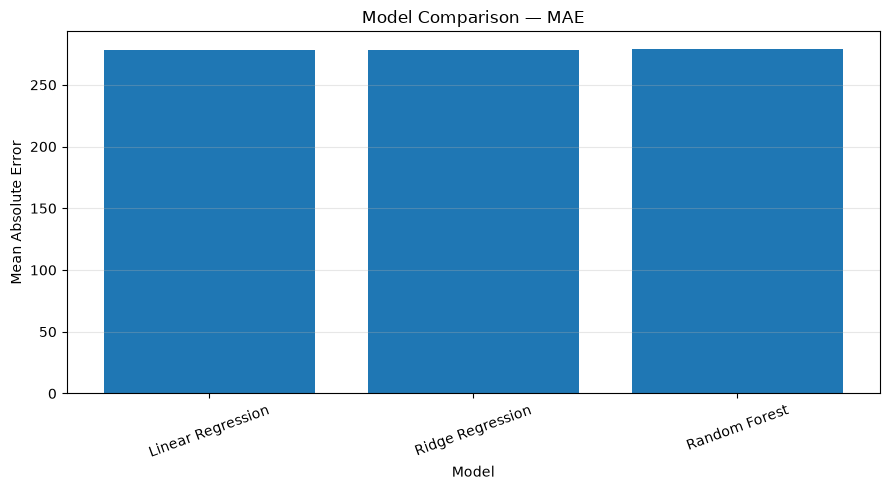

In [110]:
plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["MAE"]
)

plt.xlabel("Model")
plt.ylabel("Mean Absolute Error")
plt.title("Model Comparison — MAE")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

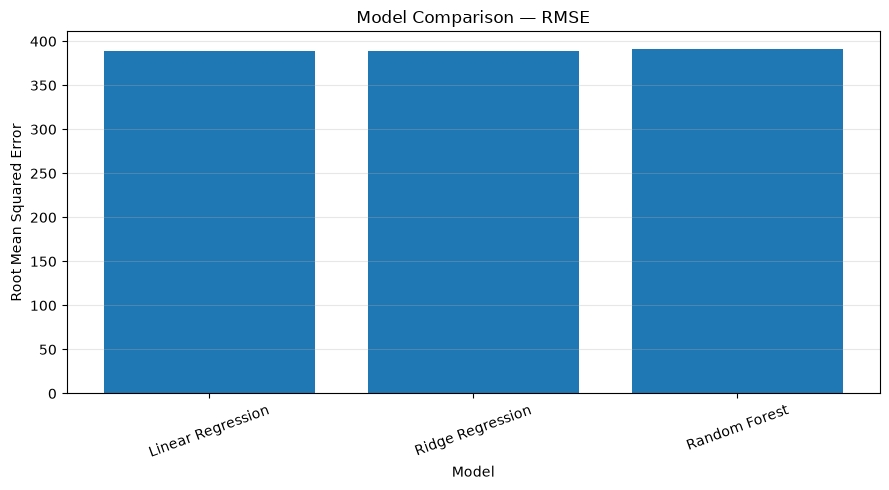

In [111]:
plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["RMSE"]
)

plt.xlabel("Model")
plt.ylabel("Root Mean Squared Error")
plt.title("Model Comparison — RMSE")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

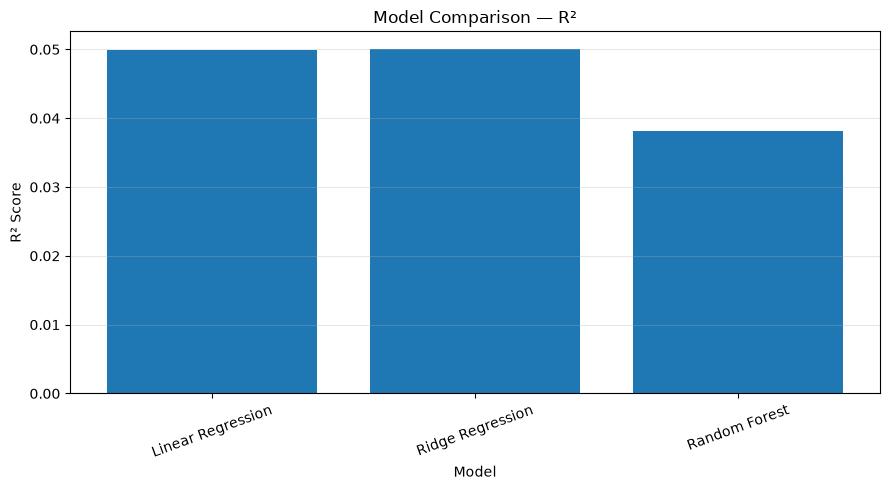

In [112]:
plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["R²"]
)

plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("Model Comparison — R²")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Actual vs Predicted Values

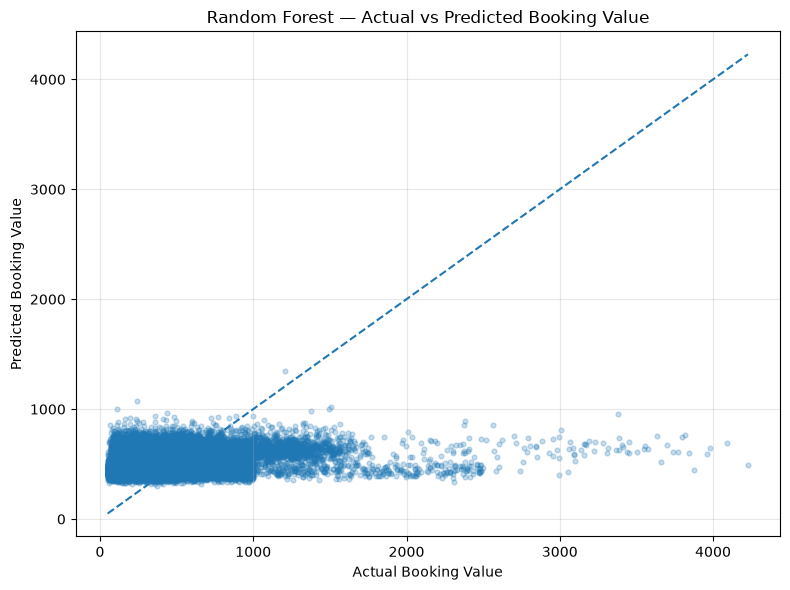

In [113]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_rf,
    alpha=0.25,
    s=12
)

min_value = min(
    y_test.min(),
    y_pred_rf.min()
)

max_value = max(
    y_test.max(),
    y_pred_rf.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Booking Value")
plt.ylabel("Predicted Booking Value")
plt.title("Random Forest — Actual vs Predicted Booking Value")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Residual Analysis

In [114]:
residuals_rf = y_test - y_pred_rf

print(
    residuals_rf.describe().round(2)
)

count    18600.00
mean         1.38
std        391.69
min       -885.26
25%       -259.73
50%        -78.11
75%        179.43
max       3736.48
Name: Booking Value, dtype: float64


In [115]:
## Investigating Large Errors

In [116]:
residual_analysis = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_rf
})

residual_analysis["Residual"] = (
    residual_analysis["Actual"]
    - residual_analysis["Predicted"]
)

residual_analysis["Absolute_Error"] = (
    residual_analysis["Residual"].abs()
)

residual_analysis.sort_values(
    "Absolute_Error",
    ascending=False
).head(10).round(2)

,Actual,Predicted,Residual,Absolute_Error
83506,4228.0,491.52,3736.48,3736.48
108963,3878.0,443.19,3434.81,3434.81
21011,4093.0,688.16,3404.84,3404.84
15775,3962.0,592.71,3369.29,3369.29
100795,3978.0,647.10,3330.90,3330.90
145736,3841.0,601.47,3239.53,3239.53
38415,3771.0,611.75,3159.25,3159.25
1883,3659.0,516.57,3142.43,3142.43
24154,3737.0,612.87,3124.13,3124.13
9360,3814.0,762.34,3051.66,3051.66


### Baseline Model

A median baseline was created to establish a reference point for evaluating the regression models. It predicts the median Booking Value from the training set for every observation in the test set.

The baseline provides a simple benchmark to determine whether the trained models offer meaningful predictive improvement.

In [117]:
baseline_value = y_train.median()

# Predict the same median value for every test observation
y_pred_baseline = np.full(len(y_test), baseline_value)

# Evaluate the baseline
baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
baseline_r2 = r2_score(y_test, y_pred_baseline)

print("Baseline prediction value:", round(baseline_value, 2))
print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))
print("Baseline R²:", round(baseline_r2, 3))

Baseline prediction value: 415.0
Baseline MAE: 274.593
Baseline RMSE: 409.572
Baseline R²: -0.052


### Largest Prediction Errors

The largest absolute prediction errors were examined to identify observations for which the model's predictions differed substantially from actual Booking Value.

This analysis helps assess whether the model struggles with unusually high booking values or other observations that are difficult to predict.

In [118]:
# Inspect Random Forest errors
rf_error_analysis = pd.DataFrame({
    "Actual_Booking_Value": np.asarray(y_test),
    "Predicted_Booking_Value": np.asarray(y_pred_rf)
})

rf_error_analysis["Residual"] = (
    rf_error_analysis["Actual_Booking_Value"]
    - rf_error_analysis["Predicted_Booking_Value"]
)

rf_error_analysis["Absolute_Error"] = (
    rf_error_analysis["Residual"].abs()
)

largest_errors = (
    rf_error_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
    .round(2)
)

largest_errors

,Actual_Booking_Value,Predicted_Booking_Value,Residual,Absolute_Error
8262,4228.0,491.52,3736.48,3736.48
11938,3878.0,443.19,3434.81,3434.81
11779,4093.0,688.16,3404.84,3404.84
1855,3962.0,592.71,3369.29,3369.29
10119,3978.0,647.10,3330.90,3330.90
4573,3841.0,601.47,3239.53,3239.53
14504,3771.0,611.75,3159.25,3159.25
12175,3659.0,516.57,3142.43,3142.43
12464,3737.0,612.87,3124.13,3124.13
14432,3814.0,762.34,3051.66,3051.66


### Check negative predictions

In [119]:
# Check predictions from each model
prediction_sets = {
    "Linear Regression": np.asarray(y_pred_linear),
    "Ridge Regression": np.asarray(y_pred_ridge),
    "Random Forest": np.asarray(y_pred_rf)
}

negative_prediction_summary = []

for model_name, predictions in prediction_sets.items():
    negative_count = int((predictions < 0).sum())

    negative_prediction_summary.append({
        "Model": model_name,
        "Negative_Predictions": negative_count,
        "Negative_Predictions_Percent": round(
            (negative_count / len(predictions)) * 100, 2
        ),
        "Minimum_Prediction": round(float(predictions.min()), 2)
    })

negative_prediction_summary = pd.DataFrame(negative_prediction_summary)

negative_prediction_summary

,Model,Negative_Predictions,Negative_Predictions_Percent,Minimum_Prediction
0,Linear Regression,0,0.0,351.62
1,Ridge Regression,0,0.0,353.73
2,Random Forest,0,0.0,298.69


In [120]:
final_model_comparison = pd.DataFrame([
    {
        "Model": "Median Baseline",
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "R2": baseline_r2
    },
    {
        "Model": "Linear Regression",
        "MAE": 278.243,
        "RMSE": 389.297,
        "R2": 0.050
    },
    {
        "Model": "Ridge Regression",
        "MAE": 278.199,
        "RMSE": 389.252,
        "R2": 0.050
    },
    {
        "Model": "Random Forest",
        "MAE": 279.363,
        "RMSE": 391.684,
        "R2": 0.038
    }
])

final_model_comparison = final_model_comparison.round(3)

final_model_comparison

,Model,MAE,RMSE,R2
0,Median Baseline,274.593,409.572,-0.052
1,Linear Regression,278.243,389.297,0.050
2,Ridge Regression,278.199,389.252,0.050
3,Random Forest,279.363,391.684,0.038


In [121]:
final_model_comparison.to_csv(
    "../Data/Processed/booking_value_model_comparison.csv",
    index=False
)

print("Final model comparison saved successfully.")

Final model comparison saved successfully.


## Model Interpretation & Final Conclusion

### Interpret Random Forest feature importance

In [122]:
# Get the fitted preprocessing step and Random Forest estimator
fitted_preprocessor = random_forest_model.named_steps["preprocessor"]
fitted_rf = random_forest_model.named_steps["model"]

# Get the names of the features after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract feature importance scores
importance_values = fitted_rf.feature_importances_

# Build a feature-importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

# Display the 15 most important features
top_15_features = feature_importance.head(15).copy()

top_15_features.round(4)

,Feature,Importance
0,numerical__Ride Distance,0.0516
1,numerical__Ride_Distance_log,0.0515
2,numerical__Avg CTAT,0.0487
3,numerical__Avg_CTAT_Log,0.0486
4,numerical__Avg VTAT,0.0464
5,numerical__Avg_VTAT_Log,0.0461
6,numerical__Day_of_Week,0.0445
7,numerical__Booking_Hour,0.0378
8,numerical__Pickup_Frequency,0.0360
9,numerical__Drop_Frequency,0.0355


In [123]:
random_forest_model.named_steps.keys()

dict_keys(['preprocessor', 'model'])

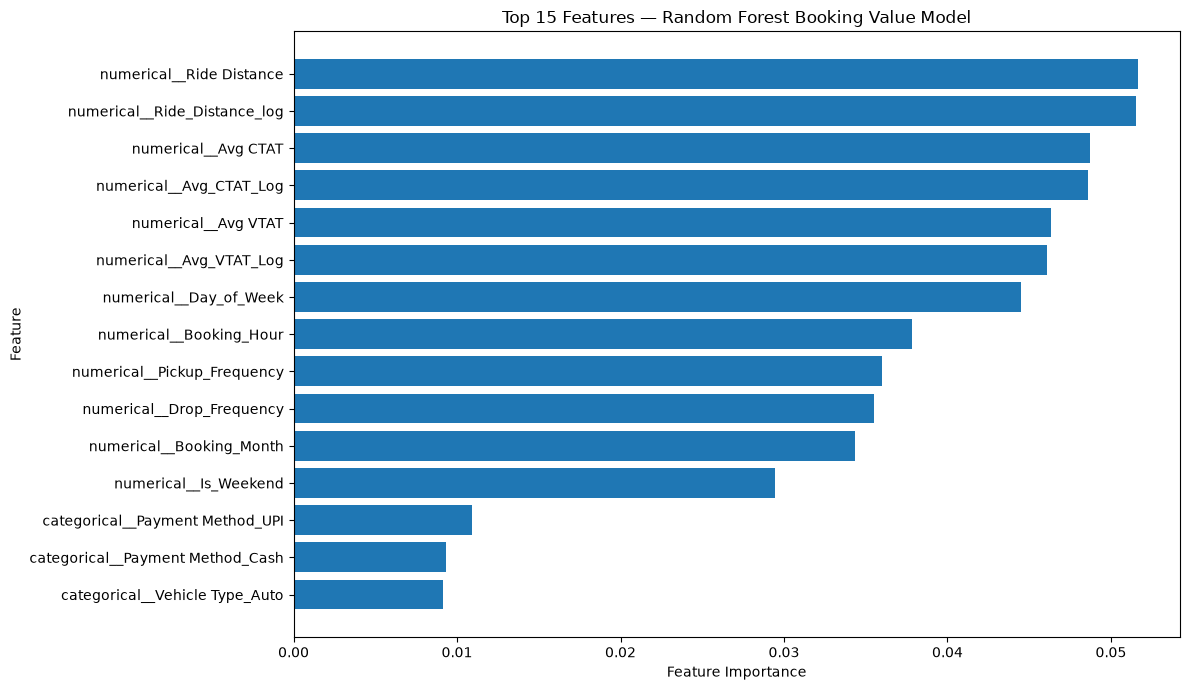

In [124]:
import matplotlib.pyplot as plt

# Reverse order so the most important feature appears at the top
plot_data = top_15_features.sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    plot_data["Feature"],
    plot_data["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features — Random Forest Booking Value Model")

plt.tight_layout()
plt.show()

### Final Conclusion

- The Booking Value regression experiment evaluated Linear Regression, Ridge Regression, and Random Forest using MAE, RMSE, and R².

- Linear Regression achieved an MAE of 278.243, RMSE of 389.297, and R² of 0.050. Ridge Regression produced nearly identical results, with an MAE of 278.199, RMSE of 389.252, and R² of 0.050. Random Forest performed slightly worse, recording an MAE of 279.363, RMSE of 391.684, and R² of 0.038.

- The models explained only a small proportion of the variation in Booking Value on the test dataset. The numerical correlation analysis also indicated weak individual relationships between Booking Value and the numerical features examined.

- A median baseline was evaluated to determine whether the trained models provided meaningful improvement over a simple prediction. The largest prediction errors and prediction validity were also examined to identify limitations.

- Overall, the experiment demonstrated the importance of evaluating regression models against a baseline rather than relying on model training alone. The results suggest that the features and modelling approaches tested did not provide strong predictive performance. Further improvement would require investigating feature quality, prediction timing, and potentially additional relevant data.

- These results describe predictive associations in the available dataset and should not be interpreted as evidence of causal relationships.